In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Dataset file paths
amazon_path = "../dataset/amazon_cells_labelled.txt"
imdb_path = "../dataset/imdb_labelled.txt"
yelp_path = "../dataset/yelp_labelled.txt"

# Load Amazon reviews
amazon = pd.read_csv(
    amazon_path,
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)

# Load IMDb reviews
imdb = pd.read_csv(
    imdb_path,
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)

# Load Yelp reviews
yelp = pd.read_csv(
    yelp_path,
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)

print("All three datasets loaded successfully!")

All three datasets loaded successfully!


Combine all three datasets

In [4]:
# Combine all datasets
df = pd.concat(
    [amazon, imdb, yelp],
    ignore_index=True
)

# Add a source column
df["source"] = (
    ["Amazon"] * len(amazon)
    + ["IMDb"] * len(imdb)
    + ["Yelp"] * len(yelp)
)

print("Combined dataset shape:", df.shape)

Combined dataset shape: (2748, 3)


In [5]:
df.head()

,review,sentiment,source
0,So there is no way for me to plug it in here i...,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more...,0,Amazon
4,The mic is great.,1,Amazon


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2748 entries, 0 to 2747
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     2748 non-null   str  
 1   sentiment  2748 non-null   int64
 2   source     2748 non-null   str  
dtypes: int64(1), str(2)
memory usage: 269.2 KB


In [7]:
print("Amazon reviews:", len(amazon))
print("IMDb reviews:", len(imdb))
print("Yelp reviews:", len(yelp))

print("\nReviews by source:")
print(df["source"].value_counts())

Amazon reviews: 1000
IMDb reviews: 748
Yelp reviews: 1000

Reviews by source:
source
Amazon    1000
Yelp      1000
IMDb       748
Name: count, dtype: int64


In [8]:
print(df["sentiment"].value_counts())

sentiment
1    1386
0    1362
Name: count, dtype: int64


In [9]:
pd.set_option("display.max_colwidth", 100)

df.head(10)

,review,sentiment,source
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,Amazon
4,The mic is great.,1,Amazon
5,I have to jiggle the plug to get it to line up right to get decent volume.,0,Amazon
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...",0,Amazon
7,If you are Razr owner...you must have this!,1,Amazon
8,"Needless to say, I wasted my money.",0,Amazon
9,What a waste of money and time!.,0,Amazon


In [10]:
print("Missing reviews:", df["review"].isna().sum())

print(
    "Empty reviews:",
    df["review"].str.strip().eq("").sum()
)

Missing reviews: 0
Empty reviews: 0


In [11]:
from pathlib import Path

# Read the original IMDb file
imdb_file = Path("../dataset/imdb_labelled.txt")

raw_text = imdb_file.read_text(encoding="utf-8", errors="replace")

# Split into individual lines
lines = raw_text.splitlines()

# Count different types of lines
total_lines = len(lines)
non_empty_lines = [line for line in lines if line.strip()]
valid_lines = [line for line in non_empty_lines if "\t" in line]
invalid_lines = [line for line in non_empty_lines if "\t" not in line]

print("Total physical lines:", total_lines)
print("Non-empty lines:", len(non_empty_lines))
print("Lines containing tabs:", len(valid_lines))
print("Lines without tabs:", len(invalid_lines))

Total physical lines: 1002
Non-empty lines: 1002
Lines containing tabs: 1000
Lines without tabs: 2


In [12]:
for i, line in enumerate(lines):
    if line.strip() and "\t" not in line:
        print(f"Line {i + 1}: {line}")

Line 179: The script is
Line 969: Definitely worth seeing


In [13]:
for line_number in [179, 969]:

    print(f"\n--- Around line {line_number} ---")

    for i in range(line_number - 3, line_number + 2):
        print(f"Line {i + 1}: {repr(lines[i])}")


--- Around line 179 ---
Line 177: 'Artless camera-work endlessly presents us with the ugliest setting imaginable, i.e.  \t0'
Line 178: 'The story is beyond stupid.  \t0'
Line 179: 'The script is'
Line 180: 'was there a script?  \t0'
Line 181: 'The kids are annoying.  \t0'

--- Around line 969 ---
Line 967: 'The incredible soundtrack truly captures the essence of the film.  \t1'
Line 968: 'Each track commands sentiment, actually contributing to the scenes and characters.  \t1'
Line 969: 'Definitely worth seeing'
Line 970: " it's the sort of thought provoking film that forces you to question your own threshold of loneliness.  \t1"
Line 971: 'Hayao Miyazaki\'s latest and eighth film for Studio Ghibili, "Gake No Ue No Ponyo" (Ponyo on the Cliff by the Sea) is a wonderfully fun and imaginative look at childhood.  \t1'


In [14]:
from io import StringIO

# Create a new list for repaired records
repaired_lines = []

i = 0

while i < len(lines):

    current_line = lines[i]

    # Check whether the line is missing a tab separator
    if current_line.strip() and "\t" not in current_line:

        # Join it with the following line
        if i + 1 < len(lines) and "\t" in lines[i + 1]:

            current_line = (
                current_line.rstrip()
                + " "
                + lines[i + 1].lstrip()
            )

            i += 1

    # Keep non-empty records
    if current_line.strip():
        repaired_lines.append(current_line)

    i += 1


# Load the repaired IMDb dataset
imdb = pd.read_csv(
    StringIO("\n".join(repaired_lines)),
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)

print("Repaired IMDb dataset shape:", imdb.shape)

Repaired IMDb dataset shape: (748, 2)


In [15]:
# Combine all three datasets again
df = pd.concat(
    [amazon, imdb, yelp],
    ignore_index=True
)

# Add source information
df["source"] = (
    ["Amazon"] * len(amazon)
    + ["IMDb"] * len(imdb)
    + ["Yelp"] * len(yelp)
)

print("Final dataset shape:", df.shape)

print("\nReviews by source:")
print(df["source"].value_counts())

Final dataset shape: (2748, 3)

Reviews by source:
source
Amazon    1000
Yelp      1000
IMDb       748
Name: count, dtype: int64


In [16]:
print("Amazon shape:", amazon.shape)
print("IMDb shape:", imdb.shape)
print("Yelp shape:", yelp.shape)

print("\nIMDb first 5 rows:")
display(imdb.head())

print("\nIMDb last 5 rows:")
display(imdb.tail())

Amazon shape: (1000, 2)
IMDb shape: (748, 2)
Yelp shape: (1000, 2)

IMDb first 5 rows:


,review,sentiment
0,"A very, very, very slow-moving, aimless movie about a distressed, drifting young man.",0
1,"Not sure who was more lost - the flat characters or the audience, nearly half of whom walked out.",0
2,"Attempting artiness with black & white and clever camera angles, the movie disappointed - became...",0
3,Very little music or anything to speak of.,0
4,The best scene in the movie was when Gerardo is trying to find a song that keeps running through...,1



IMDb last 5 rows:


,review,sentiment
743,I just got bored watching Jessice Lange take her clothes off!,0
744,"Unfortunately, any virtue in this film's production work was lost on a regrettable script.",0
745,"In a word, it is embarrassing.",0
746,Exceptionally bad!,0
747,All in all its an insult to one's intelligence and a huge waste of money.,0


In [17]:
from pathlib import Path
from io import StringIO

# Read the original IMDb file again
imdb_file = Path("../dataset/imdb_labelled.txt")
raw_text = imdb_file.read_text(encoding="utf-8", errors="replace")

lines = raw_text.splitlines()

# Repair the two split reviews
repaired_lines = []
i = 0

while i < len(lines):

    current_line = lines[i].strip()

    if current_line and "\t" not in current_line:

        # Join with the next line containing the sentiment label
        if i + 1 < len(lines) and "\t" in lines[i + 1]:
            current_line = current_line + " " + lines[i + 1].strip()
            i += 1

    if current_line and "\t" in current_line:
        repaired_lines.append(current_line)

    i += 1


# Convert repaired records into a DataFrame
imdb = pd.read_csv(
    StringIO("\n".join(repaired_lines)),
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)

print("IMDb dataset repaired!")
print("IMDb shape:", imdb.shape)
print("\nSentiment distribution:")
print(imdb["sentiment"].value_counts())

IMDb dataset repaired!
IMDb shape: (748, 2)

Sentiment distribution:
sentiment
1    386
0    362
Name: count, dtype: int64


In [18]:
df = pd.concat(
    [amazon, imdb, yelp],
    ignore_index=True
)

df["source"] = (
    ["Amazon"] * len(amazon)
    + ["IMDb"] * len(imdb)
    + ["Yelp"] * len(yelp)
)

print("Final dataset shape:", df.shape)
print(df["source"].value_counts())

Final dataset shape: (2748, 3)
source
Amazon    1000
Yelp      1000
IMDb       748
Name: count, dtype: int64


In [19]:
from pathlib import Path

imdb_file = Path("../dataset/imdb_labelled.txt")

print("File exists:", imdb_file.exists())
print("File location:", imdb_file.resolve())

raw_text = imdb_file.read_text(encoding="utf-8", errors="replace")
lines = raw_text.splitlines()

print("Total physical lines:", len(lines))
print("Line 179:", repr(lines[178]))
print("Line 180:", repr(lines[179]))
print("Line 969:", repr(lines[968]))
print("Line 970:", repr(lines[969]))

File exists: True
File location: D:\NLP-Sentiment-Analysis\dataset\imdb_labelled.txt
Total physical lines: 1002
Line 179: 'The script is'
Line 180: 'was there a script?  \t0'
Line 969: 'Definitely worth seeing'
Line 970: " it's the sort of thought provoking film that forces you to question your own threshold of loneliness.  \t1"


In [20]:
from pathlib import Path

# Read the original IMDb file
imdb_file = Path("../dataset/imdb_labelled.txt")
raw_text = imdb_file.read_text(encoding="utf-8", errors="replace")

lines = raw_text.splitlines()

# Combine broken review lines
records = []
pending = ""

for line in lines:
    line = line.strip()

    if not line:
        continue

    if "\t" in line:
        if pending:
            line = pending + " " + line
            pending = ""

        records.append(line)

    else:
        pending = (pending + " " + line).strip()

# Check for any unfinished record
print("Unfinished text:", repr(pending))

# Create the IMDb DataFrame
data = []

for record in records:
    review, sentiment = record.rsplit("\t", 1)
    data.append([review.strip(), int(sentiment.strip())])

imdb = pd.DataFrame(data, columns=["review", "sentiment"])

print("\nIMDb dataset shape:", imdb.shape)
print("\nFirst 5 reviews:")
display(imdb.head())

print("\nLast 5 reviews:")
display(imdb.tail())

Unfinished text: ''

IMDb dataset shape: (1000, 2)

First 5 reviews:


,review,sentiment
0,"A very, very, very slow-moving, aimless movie about a distressed, drifting young man.",0
1,"Not sure who was more lost - the flat characters or the audience, nearly half of whom walked out.",0
2,"Attempting artiness with black & white and clever camera angles, the movie disappointed - became...",0
3,Very little music or anything to speak of.,0
4,The best scene in the movie was when Gerardo is trying to find a song that keeps running through...,1



Last 5 reviews:


,review,sentiment
995,I just got bored watching Jessice Lange take her clothes off!,0
996,"Unfortunately, any virtue in this film's production work was lost on a regrettable script.",0
997,"In a word, it is embarrassing.",0
998,Exceptionally bad!,0
999,All in all its an insult to one's intelligence and a huge waste of money.,0


In [21]:
# Combine all three datasets
df = pd.concat(
    [amazon, imdb, yelp],
    ignore_index=True
)

# Add dataset source
df["source"] = (
    ["Amazon"] * len(amazon)
    + ["IMDb"] * len(imdb)
    + ["Yelp"] * len(yelp)
)

# Display results
print("Final dataset shape:", df.shape)

print("\nReviews by source:")
print(df["source"].value_counts())

print("\nFirst 5 rows:")
display(df.head())

Final dataset shape: (3000, 3)

Reviews by source:
source
Amazon    1000
IMDb      1000
Yelp      1000
Name: count, dtype: int64

First 5 rows:


,review,sentiment,source
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,Amazon
4,The mic is great.,1,Amazon


In [22]:
# Display dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate reviews
print("\nDuplicate Reviews:")
print(df.duplicated(subset=["review"]).sum())

# Display basic statistics
print("\nDataset Statistics:")
display(df.describe(include="all"))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     3000 non-null   str  
 1   sentiment  3000 non-null   int64
 2   source     3000 non-null   str  
dtypes: int64(1), str(2)
memory usage: 273.4 KB

Missing Values:
review       0
sentiment    0
source       0
dtype: int64

Duplicate Reviews:
18

Dataset Statistics:


,review,sentiment,source
count,3000,3000.000000,3000
unique,2982,NaN,3
top,Works great!.,NaN,Amazon
freq,2,NaN,1000
mean,NaN,0.500000,NaN
std,NaN,0.500083,NaN
min,NaN,0.000000,NaN
25%,NaN,0.000000,NaN
50%,NaN,0.500000,NaN
75%,NaN,1.000000,NaN


Remove duplicate reviews

In [23]:
# Remove duplicate reviews
df = df.drop_duplicates(subset=["review"])

# Reset index
df = df.reset_index(drop=True)

# Check the updated dataset
print("Dataset shape after removing duplicates:", df.shape)

print("\nRemaining duplicate reviews:")
print(df.duplicated(subset=["review"]).sum())

Dataset shape after removing duplicates: (2982, 3)

Remaining duplicate reviews:
0


Analyse sentiment distribution

Sentiment Distribution:
Negative reviews (0): 1492
Positive reviews (1): 1490


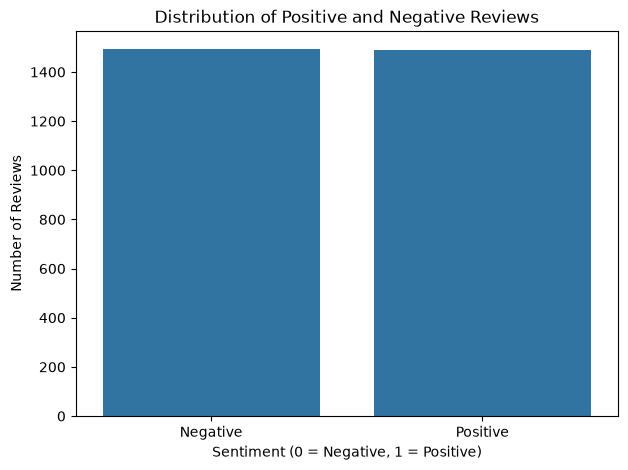

In [24]:
# Count positive and negative reviews
sentiment_counts = df["sentiment"].value_counts().sort_index()

print("Sentiment Distribution:")
print("Negative reviews (0):", sentiment_counts[0])
print("Positive reviews (1):", sentiment_counts[1])

# Visualize sentiment distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment"
)

plt.title("Distribution of Positive and Negative Reviews")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1], ["Negative", "Positive"])

plt.show()

In [25]:
print(df["sentiment"].value_counts().sort_index())

sentiment
0    1492
1    1490
Name: count, dtype: int64


Analyse review lengths

Review Length Statistics:
count    2982.000000
mean       11.879276
std         7.867669
min         1.000000
25%         6.000000
50%        10.000000
75%        16.000000
max        71.000000
Name: review_length, dtype: float64


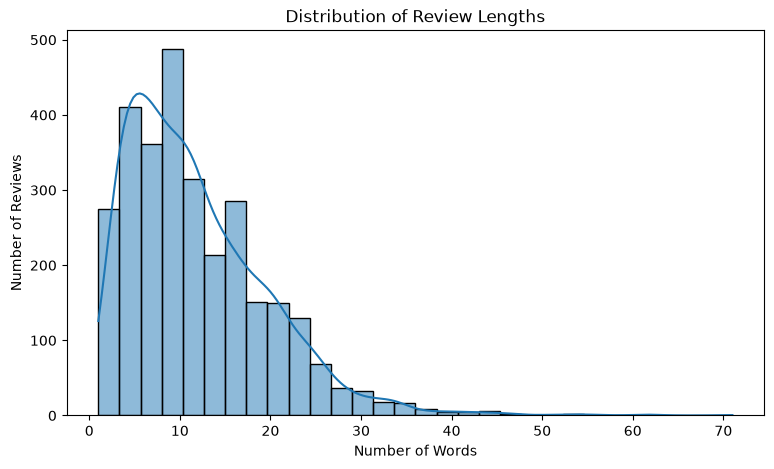

In [26]:
# Calculate the number of words in each review
df["review_length"] = df["review"].apply(
    lambda x: len(x.split())
)

# Display statistics
print("Review Length Statistics:")
print(df["review_length"].describe())

# Visualize review lengths
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="review_length",
    bins=30,
    kde=True
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

Compare review lengths by sentiment

Average Review Length by Sentiment:
sentiment
0    11.921582
1    11.836913
Name: review_length, dtype: float64


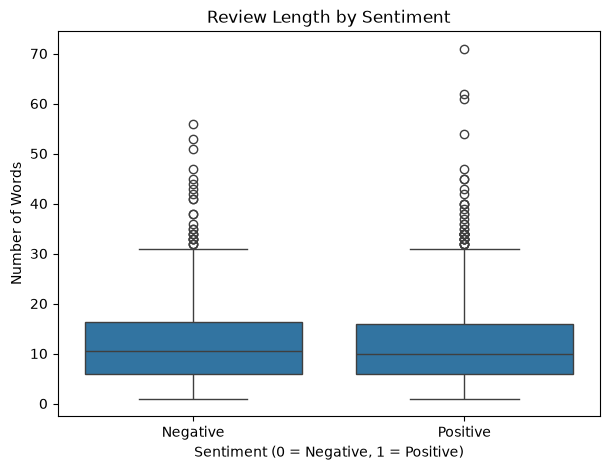

In [27]:
# Compare review lengths by sentiment
length_comparison = df.groupby("sentiment")["review_length"].mean()

print("Average Review Length by Sentiment:")
print(length_comparison)

# Visualize comparison
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="review_length"
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Words")
plt.xticks([0, 1], ["Negative", "Positive"])

plt.show()

Sentiment Distribution by Source:
sentiment    0    1
source             
Amazon     497  493
IMDb       498  498
Yelp       497  499


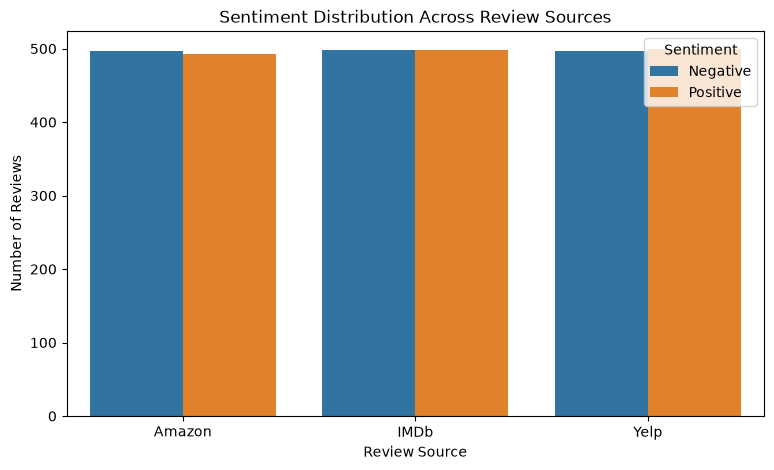

In [28]:
# Count sentiments by source
source_sentiment = pd.crosstab(
    df["source"],
    df["sentiment"]
)

print("Sentiment Distribution by Source:")
print(source_sentiment)

# Visualize sentiment by source
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="source",
    hue="sentiment"
)

plt.title("Sentiment Distribution Across Review Sources")
plt.xlabel("Review Source")
plt.ylabel("Number of Reviews")
plt.legend(
    title="Sentiment",
    labels=["Negative", "Positive"]
)

plt.show()

In [29]:
# Save the cleaned dataset
df.to_csv(
    "../dataset/cleaned_sentiment_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (2982, 4)


Text preprocessing

In [30]:
import nltk

# Download required NLTK resources
nltk.download("stopwords")
nltk.download("punkt")

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...


NLTK resources downloaded successfully!


[nltk_data]   Package punkt_tab is already up-to-date!


Converts reviews to lowercase

In [31]:
# Convert reviews to lowercase
df["cleaned_review"] = df["review"].str.lower()

# Compare original and cleaned reviews
display(df[["review", "cleaned_review"]].head(10))

,review,cleaned_review
0,So there is no way for me to plug it in here in the US unless I go by a converter.,so there is no way for me to plug it in here in the us unless i go by a converter.
1,"Good case, Excellent value.","good case, excellent value."
2,Great for the jawbone.,great for the jawbone.
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied to charger for conversations lasting more than 45 minutes.major problems!!
4,The mic is great.,the mic is great.
5,I have to jiggle the plug to get it to line up right to get decent volume.,i have to jiggle the plug to get it to line up right to get decent volume.
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...","if you have several dozen or several hundred contacts, then imagine the fun of sending each of t..."
7,If you are Razr owner...you must have this!,if you are razr owner...you must have this!
8,"Needless to say, I wasted my money.","needless to say, i wasted my money."
9,What a waste of money and time!.,what a waste of money and time!.


Remove HTML tags

In [32]:
import re

# Remove HTML tags
df["cleaned_review"] = df["cleaned_review"].apply(
    lambda text: re.sub(r"<.*?>", "", text)
)

# Display results
display(df[["review", "cleaned_review"]].head(10))

,review,cleaned_review
0,So there is no way for me to plug it in here in the US unless I go by a converter.,so there is no way for me to plug it in here in the us unless i go by a converter.
1,"Good case, Excellent value.","good case, excellent value."
2,Great for the jawbone.,great for the jawbone.
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied to charger for conversations lasting more than 45 minutes.major problems!!
4,The mic is great.,the mic is great.
5,I have to jiggle the plug to get it to line up right to get decent volume.,i have to jiggle the plug to get it to line up right to get decent volume.
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...","if you have several dozen or several hundred contacts, then imagine the fun of sending each of t..."
7,If you are Razr owner...you must have this!,if you are razr owner...you must have this!
8,"Needless to say, I wasted my money.","needless to say, i wasted my money."
9,What a waste of money and time!.,what a waste of money and time!.


Remove punctuation and special characters

In [33]:
# Remove punctuation and special characters
df["cleaned_review"] = df["cleaned_review"].apply(
    lambda text: re.sub(r"[^a-zA-Z\s]", "", text)
)

# Display original and cleaned reviews
display(df[["review", "cleaned_review"]].head(10))

,review,cleaned_review
0,So there is no way for me to plug it in here in the US unless I go by a converter.,so there is no way for me to plug it in here in the us unless i go by a converter
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied to charger for conversations lasting more than minutesmajor problems
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up right to get decent volume.,i have to jiggle the plug to get it to line up right to get decent volume
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...",if you have several dozen or several hundred contacts then imagine the fun of sending each of th...
7,If you are Razr owner...you must have this!,if you are razr owneryou must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


Correct Punctuation removal

In [34]:
# Clean text from the original reviews
df["cleaned_review"] = df["review"].apply(
    lambda text: re.sub(
        r"[^a-zA-Z\s]",
        " ",
        re.sub(r"<.*?>", " ", text.lower())
    )
)

# Remove extra spaces
df["cleaned_review"] = df["cleaned_review"].apply(
    lambda text: re.sub(r"\s+", " ", text).strip()
)

# Compare original and cleaned reviews
display(df[["review", "cleaned_review"]].head(10))

,review,cleaned_review
0,So there is no way for me to plug it in here in the US unless I go by a converter.,so there is no way for me to plug it in here in the us unless i go by a converter
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied to charger for conversations lasting more than minutes major problems
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up right to get decent volume.,i have to jiggle the plug to get it to line up right to get decent volume
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...",if you have several dozen or several hundred contacts then imagine the fun of sending each of th...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


Remove stopwords

In [35]:
from nltk.corpus import stopwords

# Load English stopwords
stop_words = set(stopwords.words("english"))

# Remove stopwords
df["cleaned_review"] = df["cleaned_review"].apply(
    lambda text: " ".join(
        word for word in text.split()
        if word not in stop_words
    )
)

# Compare original and cleaned reviews
display(df[["review", "cleaned_review"]].head(10))

,review,cleaned_review
0,So there is no way for me to plug it in here in the US unless I go by a converter.,way plug us unless go converter
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great jawbone
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied charger conversations lasting minutes major problems
4,The mic is great.,mic great
5,I have to jiggle the plug to get it to line up right to get decent volume.,jiggle plug get line right get decent volume
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...",several dozen several hundred contacts imagine fun sending one one
7,If you are Razr owner...you must have this!,razr owner must
8,"Needless to say, I wasted my money.",needless say wasted money
9,What a waste of money and time!.,waste money time


Correct stopword removal

In [37]:
import re
from nltk.corpus import stopwords

# Load English stopwords
stop_words = set(stopwords.words("english"))

# Important negative words to preserve
negation_words = {
    "no", "not", "nor", "never",
    "dont", "doesnt", "didnt",
    "isnt", "arent", "wasnt", "werent",
    "wont", "wouldnt", "couldnt", "shouldnt",
    "cant", "cannot"
}

# Remove negation words from the stopword list
stop_words = stop_words - negation_words


# Text preprocessing function
def preprocess_text(text):

    # Convert to lowercase and remove HTML tags
    text = re.sub(r"<.*?>", " ", str(text).lower())

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Remove stopwords while preserving negation words
    words = [
        word for word in text.split()
        if word not in stop_words
    ]

    return " ".join(words)


# Apply preprocessing to original reviews
df["cleaned_review"] = df["review"].apply(preprocess_text)

# Compare results
display(df[["review", "cleaned_review"]].head(10))

,review,cleaned_review
0,So there is no way for me to plug it in here in the US unless I go by a converter.,no way plug us unless go converter
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great jawbone
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied charger conversations lasting minutes major problems
4,The mic is great.,mic great
5,I have to jiggle the plug to get it to line up right to get decent volume.,jiggle plug get line right get decent volume
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...",several dozen several hundred contacts imagine fun sending one one
7,If you are Razr owner...you must have this!,razr owner must
8,"Needless to say, I wasted my money.",needless say wasted money
9,What a waste of money and time!.,waste money time


Apply stemming - Stemming reduces words to their root form by removing word endings.

In [39]:
from nltk.stem import PorterStemmer

# Create stemmer
stemmer = PorterStemmer()

# Apply stemming
df["stemmed_review"] = df["cleaned_review"].apply(
    lambda text: " ".join(
        stemmer.stem(word)
        for word in text.split()
    )
)

# Compare results
display(
    df[["review", "cleaned_review", "stemmed_review"]].head(10)
)

,review,cleaned_review,stemmed_review
0,So there is no way for me to plug it in here in the US unless I go by a converter.,no way plug us unless go converter,no way plug us unless go convert
1,"Good case, Excellent value.",good case excellent value,good case excel valu
2,Great for the jawbone.,great jawbone,great jawbon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied charger conversations lasting minutes major problems,tie charger convers last minut major problem
4,The mic is great.,mic great,mic great
5,I have to jiggle the plug to get it to line up right to get decent volume.,jiggle plug get line right get decent volume,jiggl plug get line right get decent volum
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...",several dozen several hundred contacts imagine fun sending one one,sever dozen sever hundr contact imagin fun send one one
7,If you are Razr owner...you must have this!,razr owner must,razr owner must
8,"Needless to say, I wasted my money.",needless say wasted money,needless say wast money
9,What a waste of money and time!.,waste money time,wast money time


Apply lemmatization - Lemmatization reduces words to their meaningful dictionary form rather than simply cutting off word endings.

In [40]:
import nltk

nltk.download("wordnet")
nltk.download("omw-1.4")

print("Lemmatization resources downloaded!")

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...


Lemmatization resources downloaded!


In [41]:
from nltk.stem import WordNetLemmatizer

# Create lemmatizer
lemmatizer = WordNetLemmatizer()

# Apply lemmatization
df["lemmatized_review"] = df["cleaned_review"].apply(
    lambda text: " ".join(
        lemmatizer.lemmatize(word)
        for word in text.split()
    )
)

# Compare original, cleaned, stemmed and lemmatized reviews
display(
    df[
        ["review", "cleaned_review",
         "stemmed_review", "lemmatized_review"]
    ].head(10)
)

,review,cleaned_review,stemmed_review,lemmatized_review
0,So there is no way for me to plug it in here in the US unless I go by a converter.,no way plug us unless go converter,no way plug us unless go convert,no way plug u unless go converter
1,"Good case, Excellent value.",good case excellent value,good case excel valu,good case excellent value
2,Great for the jawbone.,great jawbone,great jawbon,great jawbone
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied charger conversations lasting minutes major problems,tie charger convers last minut major problem,tied charger conversation lasting minute major problem
4,The mic is great.,mic great,mic great,mic great
5,I have to jiggle the plug to get it to line up right to get decent volume.,jiggle plug get line right get decent volume,jiggl plug get line right get decent volum,jiggle plug get line right get decent volume
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of t...",several dozen several hundred contacts imagine fun sending one one,sever dozen sever hundr contact imagin fun send one one,several dozen several hundred contact imagine fun sending one one
7,If you are Razr owner...you must have this!,razr owner must,razr owner must,razr owner must
8,"Needless to say, I wasted my money.",needless say wasted money,needless say wast money,needless say wasted money
9,What a waste of money and time!.,waste money time,wast money time,waste money time


In [42]:
# Correct lemmatization
def apply_lemmatization(text):
    words = []

    for word in text.split():
        if word == "us":
            words.append(word)
        else:
            words.append(lemmatizer.lemmatize(word))

    return " ".join(words)


df["lemmatized_review"] = df["cleaned_review"].apply(
    apply_lemmatization
)

display(
    df[["cleaned_review", "lemmatized_review"]].head(10)
)

,cleaned_review,lemmatized_review
0,no way plug us unless go converter,no way plug us unless go converter
1,good case excellent value,good case excellent value
2,great jawbone,great jawbone
3,tied charger conversations lasting minutes major problems,tied charger conversation lasting minute major problem
4,mic great,mic great
5,jiggle plug get line right get decent volume,jiggle plug get line right get decent volume
6,several dozen several hundred contacts imagine fun sending one one,several dozen several hundred contact imagine fun sending one one
7,razr owner must,razr owner must
8,needless say wasted money,needless say wasted money
9,waste money time,waste money time


Convert text into numerical features using TF-IDF

Import TfidfVectorizer

In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer

print("TF-IDF imported successfully!")

TF-IDF imported successfully!


In [44]:
# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

# Convert reviews into numerical features
X = tfidf.fit_transform(df["lemmatized_review"])

# Target variable
y = df["sentiment"]

# Display results
print("TF-IDF transformation completed!")

print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)
print("Number of unique features:", len(tfidf.get_feature_names_out()))

TF-IDF transformation completed!
Feature matrix shape: (2982, 5000)
Target variable shape: (2982,)
Number of unique features: 5000


Split the dataset

In [45]:
from sklearn.model_selection import train_test_split

print("Train-test split imported successfully!")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Train-test split imported successfully!
Training and testing split completed!
X_train shape: (2385, 5000)
X_test shape: (597, 5000)
y_train shape: (2385,)
y_test shape: (597,)


Prevent data leakage

In [46]:
# Split text and sentiment labels
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["lemmatized_review"],
    df["sentiment"],
    test_size=0.20,
    random_state=42,
    stratify=df["sentiment"]
)

# Create a fresh TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

# Fit only on training reviews
X_train = tfidf.fit_transform(X_train_text)

# Transform testing reviews
X_test = tfidf.transform(X_test_text)

print("Leakage-safe TF-IDF transformation completed!")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Leakage-safe TF-IDF transformation completed!
X_train shape: (2385, 5000)
X_test shape: (597, 5000)
y_train shape: (2385,)
y_test shape: (597,)


Multinomial Naive Bayes

In [47]:
from sklearn.naive_bayes import MultinomialNB

print("Naive Bayes imported successfully!")

Naive Bayes imported successfully!


In [48]:
# Create Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [49]:
# Predict sentiment for test reviews
y_pred_nb = nb_model.predict(X_test)

print("Predictions completed!")

# Display first 10 predictions
print("Actual sentiments:", y_test.values[:10])
print("Predicted sentiments:", y_pred_nb[:10])

Predictions completed!
Actual sentiments: [0 0 0 1 0 0 1 1 0 0]
Predicted sentiments: [0 0 1 1 1 1 1 1 0 0]


Evaluate Naive Bayes

In [50]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_nb,
        target_names=["Negative", "Positive"]
    )
)

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes Accuracy: 80.07 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.78      0.80       299
    Positive       0.79      0.82      0.80       298

    accuracy                           0.80       597
   macro avg       0.80      0.80      0.80       597
weighted avg       0.80      0.80      0.80       597


Confusion Matrix:
[[233  66]
 [ 53 245]]


Logistic Regression

In [51]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [52]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["Negative", "Positive"]
    )
)

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 79.56 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.80      0.79      0.79       299
    Positive       0.79      0.81      0.80       298

    accuracy                           0.80       597
   macro avg       0.80      0.80      0.80       597
weighted avg       0.80      0.80      0.80       597


Confusion Matrix:
[[235  64]
 [ 58 240]]


Support Vector Machine (SVM)

In [53]:
from sklearn.svm import LinearSVC

# Create the SVM model
svm_model = LinearSVC()

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test)

print("SVM model trained successfully!")

SVM model trained successfully!


In [54]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=["Negative", "Positive"]
    )
)

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

SVM Accuracy: 81.07 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.81      0.81       299
    Positive       0.81      0.82      0.81       298

    accuracy                           0.81       597
   macro avg       0.81      0.81      0.81       597
weighted avg       0.81      0.81      0.81       597


Confusion Matrix:
[[241  58]
 [ 55 243]]


Random Forest

In [55]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [56]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Negative", "Positive"]
    )
)

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 78.73 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.75      0.86      0.80       299
    Positive       0.84      0.71      0.77       298

    accuracy                           0.79       597
   macro avg       0.79      0.79      0.79       597
weighted avg       0.79      0.79      0.79       597


Confusion Matrix:
[[258  41]
 [ 86 212]]


Model Comparison

In [57]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "SVM",
        "Random Forest"
    ],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy,
        rf_accuracy
    ]
})

# Convert accuracy into percentages
model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

# Sort models by accuracy
model_comparison = model_comparison.sort_values(
    by="Accuracy",
    ascending=False
)

display(model_comparison[["Model", "Accuracy (%)"]])

,Model,Accuracy (%)
2,SVM,81.07
0,Naive Bayes,80.07
1,Logistic Regression,79.56
3,Random Forest,78.73


In [58]:
model_comparison = model_comparison.reset_index(drop=True)

display(model_comparison[["Model", "Accuracy (%)"]])

,Model,Accuracy (%)
0,SVM,81.07
1,Naive Bayes,80.07
2,Logistic Regression,79.56
3,Random Forest,78.73


In [59]:
model_comparison.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


Create new customer reviews

In [60]:
# New customer reviews
new_reviews = [
    "This product is absolutely amazing and works perfectly.",
    "I am very disappointed with this product.",
    "The quality is excellent and I love it.",
    "Terrible experience. I would never buy this again.",
    "The product is okay, nothing special."
]

Preprocess the new reviews

In [61]:
# Apply the existing preprocessing and lemmatization
new_cleaned_reviews = [
    apply_lemmatization(preprocess_text(review))
    for review in new_reviews
]

print("Preprocessed Reviews:\n")

for review in new_cleaned_reviews:
    print(review)

Preprocessed Reviews:

product absolutely amazing work perfectly
disappointed product
quality excellent love
terrible experience would never buy
product okay nothing special


Convert new reviews into TF-IDF

In [62]:
# Transform new reviews using the existing TF-IDF vectorizer
new_reviews_tfidf = tfidf.transform(new_cleaned_reviews)

print("New reviews converted into TF-IDF successfully!")
print("Shape:", new_reviews_tfidf.shape)

New reviews converted into TF-IDF successfully!
Shape: (5, 5000)


In [63]:
# Predict sentiments using the trained SVM model
new_predictions = svm_model.predict(new_reviews_tfidf)

# Display predictions
for review, prediction in zip(new_reviews, new_predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 60)

Review: This product is absolutely amazing and works perfectly.
Predicted Sentiment: Positive
------------------------------------------------------------
Review: I am very disappointed with this product.
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The quality is excellent and I love it.
Predicted Sentiment: Positive
------------------------------------------------------------
Review: Terrible experience. I would never buy this again.
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The product is okay, nothing special.
Predicted Sentiment: Negative
------------------------------------------------------------


Save the treained SVM model

In [64]:
import joblib

# Save the trained SVM model
joblib.dump(svm_model, "../models/svm_sentiment_model.pkl")

# Save the TF-IDF vectorizer
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("SVM model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

SVM model saved successfully!
TF-IDF vectorizer saved successfully!


In [65]:
from pathlib import Path

model_path = Path("../models/svm_sentiment_model.pkl")
vectorizer_path = Path("../models/tfidf_vectorizer.pkl")

print("SVM model exists:", model_path.exists())
print("TF-IDF vectorizer exists:", vectorizer_path.exists())

SVM model exists: True
TF-IDF vectorizer exists: True
